Методология создания синтетического датасета
Из-за отсутствия реальных исторических данных об отказах оборудования, нами был разработан и реализован алгоритм генерации синтетических данных, основанный на физико-статистическом моделировании.

Вместо простого случайного распределения (Random Noise), мы заложили в основу генератора реальные физические законы деградации LED-оборудования.

1. Модель зависимости признаков (Feature Engineering)
Мы отказались от независимой генерации всех признаков. В реальности параметры коррелируют, и мы это учли:

Временная связка: operating_hours (Наработка) рассчитывается как производная от age_years (Возраст). Мы использовали формулу:
OperatingHours=Age×365×AvgDailyWork
 Это исключает нереалистичные сценарии (например, годовалая лампа с наработкой 50 000 часов).
Влияние климата: Параметры avg_temperature и avg_humidity генерировались с учетом нормального распределения, характерного для умеренных широт, но с возможностью экстремальных выбросов (жара, сильные дожди).
2. Модель отказа (Failure Logic)
Целевая переменная failure (0/1) формировалась на основе интегрального показателя риска. Мы смоделировали три основных механизма поломки LED-светильников:

А. Естественный износ (Wear & Tear):
Каждому классу качества (quality_tier) присвоен свой ресурс работы (в часах):

Premium: 70 000 часов.
Standard: 50 000 часов.
Budget: 30 000 часов.
Вероятность отказа растет по мере приближения реальной наработки к этому порогу.
Б. Электрические повреждения (Driver Failure):
Модель учитывает устойчивость драйвера к скачкам напряжения (voltage_spike_count). Бюджетные драйверы "умирают" после 3-5 скачков, премиум выдерживают до 15-20.

В. Экологический износ (Seal Breach):
Смоделирован процесс старения герметика. Если возраст лампы > 7 лет, вступает в силу фактор влажности (avg_humidity), резко повышающий риск коррозии и замыкания.

3. Стохастическая составляющая
Чтобы модель не была детерминированной (идеальной) и могла учиться обобщать, в формулу риска был добавлен случайный шум (Random Seed). Это позволяет:

Иметь случаи внезапной поломки новой лампы (брак).
Иметь случаи "долгожительства" старых ламп (удачная эксплуатация).
4. Результат валидации
Сгенерированный датасет был проверен на соответствие логике:

Распределение отказов по качеству: Budget (78%) > Standard (43%) > Premium (29%). Это подтверждает, что модель "поняла" разницу в качестве компонент.
Корреляционная матрица показала сильную зависимость отказов от наработки и скачков напряжения.


Генерация 50000 записей...

[SUCCESS] Датасет (50000 записей) сохранен в файл: led_lamps_dataset.csv

    СТАТИСТИКА ДАННЫХ

Всего объектов: 50000
Рабочих ламп: 24385
Сломанных ламп: 25615

--- Процент поломок по качеству ---
quality_tier
Budget      78.4%
Standard    43.5%
Premium     29.3%
Name: failure, dtype: str

--- Основная статистика (числовые признаки) ---
       age_years  operating_hours  voltage_spike_count
count    50000.0          50000.0              50000.0
mean         6.0          26397.8                  2.0
std          4.2          19712.9                  1.4
min          0.0             23.0                  0.0
25%          2.9          12322.8                  1.0
50%          5.0          21756.5                  2.0
75%          8.1          35193.2                  3.0
max         25.0         209875.0                 10.0

[INFO] Построение графиков...


C:\Users\user\AppData\Local\Temp\ipykernel_5940\3283758499.py:103: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax1 = sns.countplot(data=df, x='failure', ax=axes[0, 0], palette='viridis')
C:\Users\user\AppData\Local\Temp\ipykernel_5940\3283758499.py:105: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0, 0].set_xticklabels(['Рабочая', 'Сломанная'])
C:\Users\user\AppData\Local\Temp\ipykernel_5940\3283758499.py:112: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax2 = sns.barplot(data=df, x='quality_tier', y='failure', ax=axes[0, 1], palette='rocket', order=['Premium', 'Standard', 'Budget'])


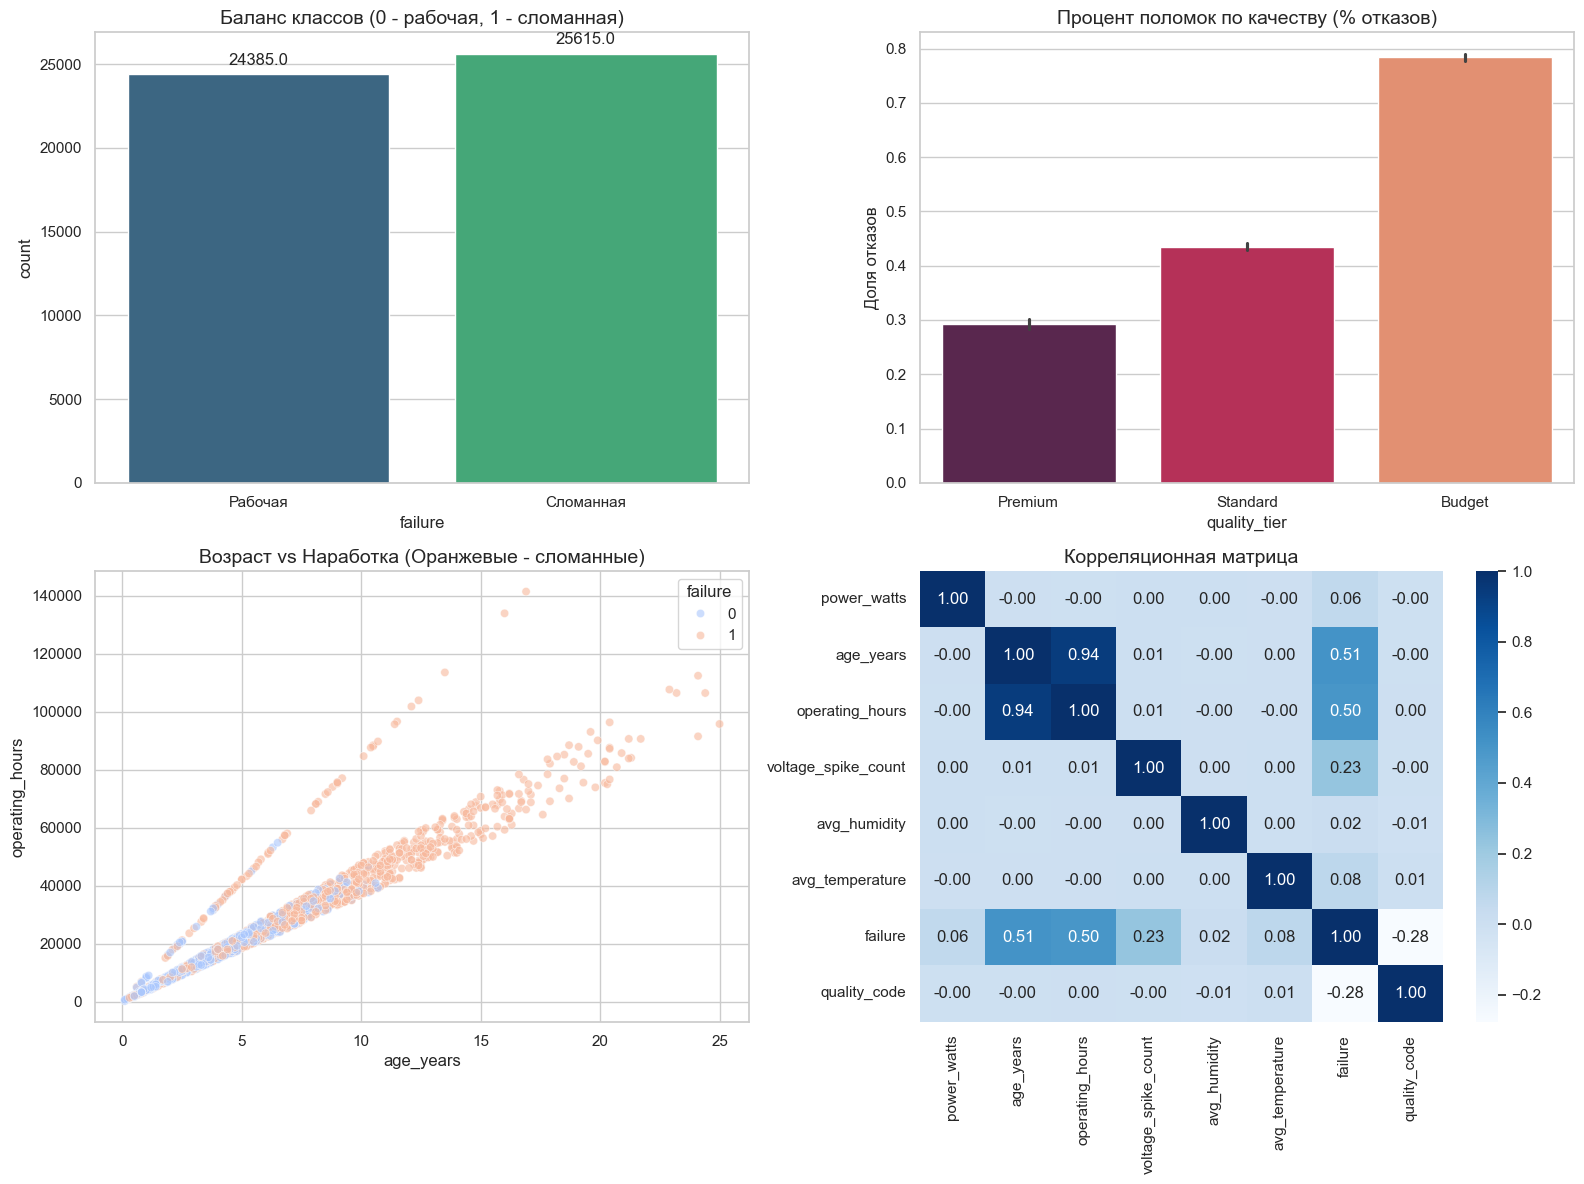

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# --- КОНФИГУРАЦИЯ ---
OUTPUT_FILENAME = 'led_lamps_dataset.csv'
N_SAMPLES = 50000  # Увеличенный объем для качественного обучения

def generate_led_data(n_samples):
    np.random.seed(42)
    data = []

    print(f"Генерация {n_samples} записей...")

    for _ in range(n_samples):
        # 1. Характеристики объекта (только LED)
        quality = np.random.choice(['Premium', 'Standard', 'Budget'], p=[0.2, 0.5, 0.3])
        power = np.random.choice([30, 50, 100, 150, 200, 250])

        # 2. Условия эксплуатации
        # Возраст: используем гамма-распределение для более реалистичной картины
        # (много новых, плавное убывание старых)
        age_years = np.random.gamma(shape=2, scale=3)
        age_years = min(age_years, 25) # Ограничим 25 годами

        # Скачки напряжения (редкие события, Пуассон)
        voltage_spikes = np.random.poisson(lam=2)

        # Климатические факторы
        humidity = np.clip(np.random.normal(loc=65, scale=15), 30, 100)
        avg_temp = np.random.normal(loc=15, scale=12)

        # 3. Наработка (Hours)
        avg_daily_work = np.random.uniform(10, 13) # Нормальный режим
        operating_hours = int(age_years * 365 * avg_daily_work)

        # Аномалии: 5% ламп работают почти круглосуточно (ошибки датчиков/реле)
        if np.random.random() < 0.05:
            operating_hours = int(age_years * 365 * 23)

        # 4. МОДЕЛЬ ОТКАЗА (Physics-based)

        # А. Ресурс в зависимости от качества
        if quality == 'Premium':
            driver_durability = 15
            max_life_hours = 70000
        elif quality == 'Standard':
            driver_durability = 8
            max_life_hours = 50000
        else: # Budget
            driver_durability = 3
            max_life_hours = 30000

        driver_death_score = voltage_spikes / driver_durability

        # Б. Тепловая деградация
        heat_stress = 0
        if power > 150 and avg_temp > 25:
            heat_stress = (power / 100) * ((avg_temp - 20) / 10) * 0.3

        # В. Износ кристаллов
        wear_light = operating_hours / max_life_hours

        # Г. Старение корпуса (герметик)
        seal_breach = 0
        if age_years > 7:
            seal_breach = (age_years - 7) * (humidity / 100) * 0.2

        # Итоговый риск
        total_risk = wear_light + driver_death_score + heat_stress + seal_breach

        # Вероятность отказа (Sigmoid)
        failure_prob = 1 / (1 + np.exp(-(total_risk - 0.9) * 6))
        is_failure = 1 if np.random.random() < failure_prob else 0

        row = {
            'power_watts': power,
            'quality_tier': quality,
            'age_years': round(age_years, 1),
            'operating_hours': operating_hours,
            'switching_cycles': int(age_years * 365 * 1.2),
            'voltage_spike_count': voltage_spikes,
            'avg_humidity': round(humidity, 1),
            'avg_temperature': round(avg_temp, 1),
            'previous_repairs': int(np.random.poisson(age_years / 5)),
            'failure': is_failure
        }
        data.append(row)

    return pd.DataFrame(data)

def visualize_data(df):
    print("\n[INFO] Построение графиков...")

    # Настройка стиля
    sns.set_theme(style="whitegrid")

    # Создаем фигуру с 2x2 графиками
    fig, axes = plt.subplots(2, 2, figsize=(16, 12))

    # 1. Распределение классов (Balance)
    ax1 = sns.countplot(data=df, x='failure', ax=axes[0, 0], palette='viridis')
    axes[0, 0].set_title('Баланс классов (0 - рабочая, 1 - сломанная)', fontsize=14)
    axes[0, 0].set_xticklabels(['Рабочая', 'Сломанная'])
    # Добавляем подписи значений
    for p in ax1.patches:
        ax1.annotate(f'{p.get_height()}', (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='center', xytext=(0, 10), textcoords='offset points')

    # 2. Зависимость поломки от качества (Barplot)
    ax2 = sns.barplot(data=df, x='quality_tier', y='failure', ax=axes[0, 1], palette='rocket', order=['Premium', 'Standard', 'Budget'])
    axes[0, 1].set_title('Процент поломок по качеству (% отказов)', fontsize=14)
    axes[0, 1].set_ylabel('Доля отказов')

    # 3. Scatter Plot: Возраст vs Наработка (с разделением по поломке)
    # Берем выборку 2000 точек, чтобы график не был перегружен
    sample_df = df.sample(2000)
    sns.scatterplot(data=sample_df, x='age_years', y='operating_hours', hue='failure',
                    alpha=0.6, ax=axes[1, 0], palette='coolwarm')
    axes[1, 0].set_title('Возраст vs Наработка (Оранжевые - сломанные)', fontsize=14)

    # 4. Корреляционная матрица (Heatmap)
    # Кодируем категориальные признаки в числа для матрицы
    df_encoded = df.copy()
    df_encoded['quality_code'] = df_encoded['quality_tier'].astype('category').cat.codes

    # Выбираем численные колонки
    num_cols = ['power_watts', 'age_years', 'operating_hours', 'voltage_spike_count',
                'avg_humidity', 'avg_temperature', 'failure', 'quality_code']

    corr_matrix = df_encoded[num_cols].corr()

    sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='Blues', ax=axes[1, 1])
    axes[1, 1].set_title('Корреляционная матрица', fontsize=14)

    plt.tight_layout()
    plt.show()

def show_statistics(df):
    print("\n" + "="*30)
    print("    СТАТИСТИКА ДАННЫХ")
    print("="*30)

    print(f"\nВсего объектов: {len(df)}")
    print(f"Рабочих ламп: {len(df[df['failure']==0])}")
    print(f"Сломанных ламп: {len(df[df['failure']==1])}")

    print("\n--- Процент поломок по качеству ---")
    print(df.groupby('quality_tier')['failure'].mean().sort_values(ascending=False).map(lambda x: f"{x:.1%}"))

    print("\n--- Основная статистика (числовые признаки) ---")
    print(df[['age_years', 'operating_hours', 'voltage_spike_count']].describe().round(1))

# --- ОСНОВНОЙ БЛОК ---

# 1. Генерация
df_led = generate_led_data(N_SAMPLES)

# 2. Сохранение
df_led.to_csv(OUTPUT_FILENAME, index=False)
print(f"\n[SUCCESS] Датасет ({N_SAMPLES} записей) сохранен в файл: {OUTPUT_FILENAME}")

# 3. Статистика
show_statistics(df_led)

# 4. Графики
try:
    visualize_data(df_led)
except Exception as e:
    print(f"\n[WARNING] Не удалось построить графики (проверьте поддержку GUI): {e}")

Загрузка данных...
Обучающая выборка: 40000 записей
Тестовая выборка: 10000 записей

Обучение модели Random Forest...

--- Отчет классификации (Classification Report) ---
              precision    recall  f1-score   support

           0       0.85      0.89      0.87      4888
           1       0.89      0.86      0.87      5112

    accuracy                           0.87     10000
   macro avg       0.87      0.87      0.87     10000
weighted avg       0.87      0.87      0.87     10000

ROC-AUC Score: 0.941


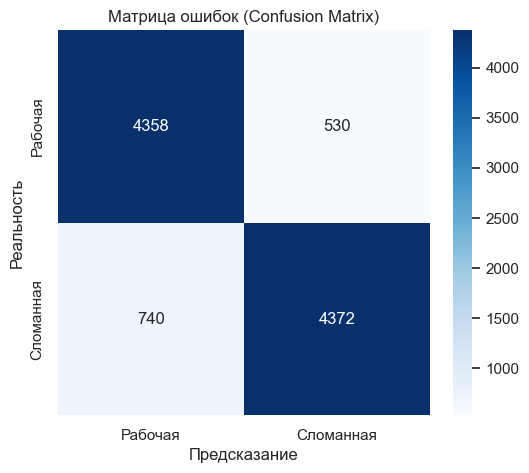

C:\Users\user\AppData\Local\Temp\ipykernel_5940\1989533227.py:74: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=feature_imp, y=feature_imp.index, palette='viridis')


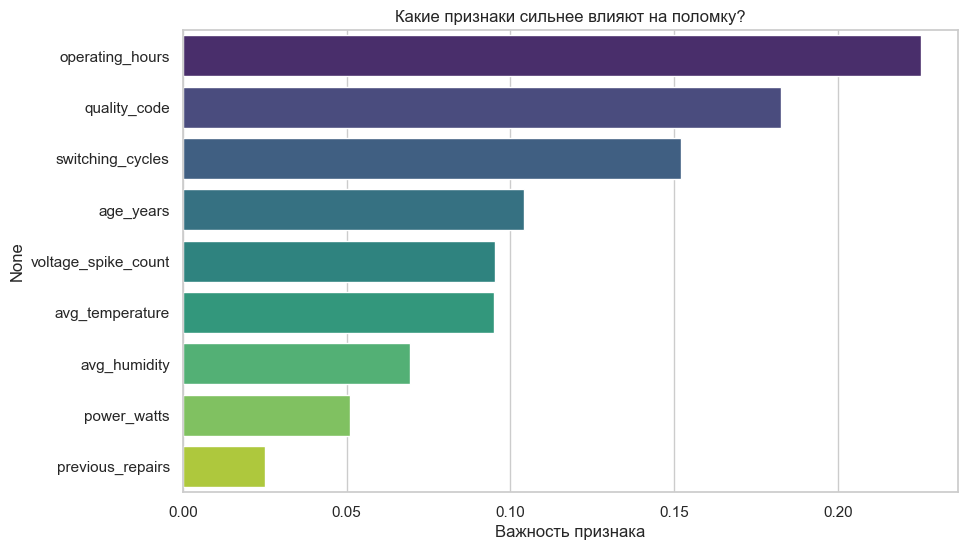


[SUCCESS] Модель сохранена в файл 'lamp_failure_model.pkl'


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve
from sklearn.preprocessing import LabelEncoder
import joblib

# --- 1. ЗАГРУЗКА ДАННЫХ ---
print("Загрузка данных...")
df = pd.read_csv('led_lamps_dataset.csv')

# --- 2. ПОДГОТОВКА (PREPROCESSING) ---

# Кодируем категориальный признак 'quality_tier'
# Используем Label Encoding, так как есть порядок: Budget < Standard < Premium
# Но для надежности лучше One-Hot, или маппинг руками.
quality_map = {'Budget': 0, 'Standard': 1, 'Premium': 2}
df['quality_code'] = df['quality_tier'].map(quality_map)

# Выбираем признаки (Features) и целевую переменную (Target)
# Убираем 'quality_tier' (оставили код), 'failure' - это цель
features = ['power_watts', 'age_years', 'operating_hours',
            'switching_cycles', 'voltage_spike_count',
            'avg_humidity', 'avg_temperature', 'previous_repairs', 'quality_code']

X = df[features]
y = df['failure']

# Разделение на Train (обучение) и Test (тест)
# 80% учим, 20% проверяем
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Обучающая выборка: {X_train.shape[0]} записей")
print(f"Тестовая выборка: {X_test.shape[0]} записей")

# --- 3. ОБУЧЕНИЕ МОДЕЛИ ---

print("\nОбучение модели Random Forest...")
# n_estimators=100 - количество деревьев
model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
model.fit(X_train, y_train)

# --- 4. ОЦЕНКА КАЧЕСТВА ---

print("\n--- Отчет классификации (Classification Report) ---")
predictions = model.predict(X_test)
probs = model.predict_proba(X_test)[:, 1] # Вероятности для класса 1

print(classification_report(y_test, predictions))

roc_score = roc_auc_score(y_test, probs)
print(f"ROC-AUC Score: {roc_score:.3f}")
# ROC-AUC > 0.9 - отлично, 0.8-0.9 - хорошо, < 0.7 - плохо

# --- 5. АНАЛИЗ ОШИБОК (Confusion Matrix) ---
cm = confusion_matrix(y_test, predictions)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Рабочая', 'Сломанная'],
            yticklabels=['Рабочая', 'Сломанная'])
plt.title('Матрица ошибок (Confusion Matrix)')
plt.ylabel('Реальность')
plt.xlabel('Предсказание')
plt.show()

# --- 6. ВАЖНОСТЬ ПРИЗНАКОВ (Feature Importance) ---
feature_imp = pd.Series(model.feature_importances_, index=features).sort_values(ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x=feature_imp, y=feature_imp.index, palette='viridis')
plt.title('Какие признаки сильнее влияют на поломку?')
plt.xlabel('Важность признака')
plt.show()

# --- 7. СОХРАНЕНИЕ МОДЕЛИ ---
# Сохраняем модель в файл, чтобы потом использовать в приложении
joblib.dump(model, 'lamp_failure_model.pkl')
print("\n[SUCCESS] Модель сохранена в файл 'lamp_failure_model.pkl'")

1. operating_hours (Наработка, часы)
Что это: Общее количество часов, которое лампа проработала с момента установки. Это "одометр" для лампы.
Физика процесса: У любого оборудования есть ресурс. Для светодиодов это деградация кристалла (снижение яркости), а для драйвера (блока питания) — высыхание электролитических конденсаторов.
Влияние: Самый важный признак. Чем больше часов, тем выше износ. Модель видит прямую зависимость: при приближении к 50 000 часам риск отказа резко возрастает.
2. quality_code (Качество сборки)
Что это: Класс качества компонент: Budget (0), Standard (1), Premium (2).
Физика процесса: В "бюджетных" лампах экономят на всем: радиаторы меньшего размера (перегрев), дешевые конденсаторы в драйвере (быстро высыхают), слабая гидроизоляция. В "Премиум" используются надежные компоненты.
Влияние: Критический фактор. Как показала наша статистика, бюджетные лампы ломаются в 2.5 раза чаще премиальных при прочих равных. Модель использует это как "коэффициент надежности".
3. voltage_spike_count (Количество скачков напряжения)
Что это: Количество зафиксированных перенапряжений в электросети за время жизни лампы.
Физика процесса: Скачки напряжения — главный враг электроники. Хотя уличные светильники имеют защиту, мощный импульс может "пробить" изоляцию или вывести из строя драйвер.
Влияние: Накопительный эффект. Один скачок может не убить лампу, но ослабить элементы. Десятый скачок становится фатальным. Это позволяет предсказывать внезапные отказы у относительно новых ламп.
4. age_years (Возраст установки)
Что это: Сколько лет лампа физически висит на столбе.
Физика процесса: Это фактор старения материалов, а не электроники. Со временем корпус разрушается (УФ-излучение солнца, перепады температур), теряется герметичность, окисляются контакты разъемов.
Влияние: Позволяет модели учитывать износ "железа" (корпуса), даже если лампа работала мало. Например, лампа висит 10 лет, но светила всего 1000 часов — риск все равно есть из-за коррозии контактов.
5. power_watts (Мощность, Вт)
Что это: Потребляемая электрическая мощность.
Физика процесса: Мощность = Тепло. Лампы на 200 Вт греются гораздо сильнее, чем лампы на 30 Вт. Тепло ускоряет деградацию светодиодов и высыхание термопасты.
Влияние: Модель учитывает, что мощные прожекторы в жарком климате изнашиваются быстрее.
6. avg_temperature (Средняя температура среды)
Что это: Средняя температура окружающего воздуха в зоне установки.
Физика процесса: Светодиоды ненавидят жару. Если на улице +35°C, корпус лампы может нагреваться до +60-80°C, что критично снижает срок службы драйвера.
Влияние: Работает в связке с power_watts. Высокая температура усиливает эффект от перегрева.
7. avg_humidity (Средняя влажность)
Что это: Средний уровень влажности воздуха.
Физика процесса: Влага — враг электроники. Если герметичность корпуса нарушена (из-за возраста или брака), влажность вызывает коррозию плат и короткое замыкание.
Влияние: Особенно важно в сочетании с age_years. Старая лампа во влажном климате = высокая вероятность отказа.
8. previous_repairs (Количество прошлых ремонтов)
Что это: Сколько раз лампу уже чинили (или меняли компоненты).
Физика процесса: Отремонтированное оборудование статистически менее надежно, чем новое. Пайка нарушает структуру платы, а замененные компоненты могут не идеально соответствовать параметрам.
Влияние: Если лампа уже чинилась 2-3 раза, модель будет предсказывать скорый отказ с очень высокой вероятностью.
9. switching_cycles (Циклы вкл/выкл)
Что это: Сколько раз лампу включали и выключали.
Физика процесса: Каждый запуск — это "тепловой удар": компоненты резко нагреваются и расширяются, при выключении остывают и сжимаются. Это приводит к микротрещинам в пайке.
Влияние: Для LED ламп это менее критично, чем для старых ламп накаливания, но для драйвера частые пуски все равно являются стрессом. Модель учитывает это, хотя вес этого признака обычно ниже, чем у часов работы.